# 00 · Instance explorer

Choisis une instance (et éventuellement un placement) dans la cellule **Paramètres**, puis lance tout (*Run All*). Le notebook génère :

1. le **graphe d'interaction** du circuit ;
2. la **puce** avec le placement et les interactions superposées ;
3. les **matrices** : portes entre qubits, distances physiques, contributions au coût ;
4. les **degrés** : logiques vs physiques ;
5. le **circuit** : dessin Qiskit et carte compacte des portes ;
6. l'**évaluation** du placement avec la vraie fitness et le circuit routé.

Les couleurs suivent le cours : **orange = qubits logiques**, **bleu = qubits physiques**. Pour les distances : vert = voisins, jaune = distance 2, rouge = distance ≥ 3.

In [17]:
# Bibliothèques générales.
import math

import networkx as nx  # graphes et disposition automatique des sommets
import numpy as np  # calcul sur tableaux
import pandas as pd  # tableaux de données
from matplotlib.lines import Line2D  # éléments de légende personnalisés

# Nos outils : pont vers source.py, données de circuit, coordonnées des puces.
from goc import circuit_data, hardware, source_bridge
# Socle d'optimisation : chargement d'instance, vraie fitness, coût de distance.
from optimizer import Problem, direct_gate_ratio, distance_cost, load_instance, pair_distances

In [18]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

In [19]:
# Numéro de l'instance à explorer (1 à 9).
INSTANCE_ID = 3
# Placement à visualiser : None = identité [0, 1, ..., n-1], sinon une liste de n qubits physiques.
MAPPING = None
# Nombre de vraies évaluations du placement (section 6), pour voir le bruit.
EVALUATION_RUNS = 10
# Au-delà de ce nombre de portes, le dessin Qiskit complet devient illisible et n'est pas affiché.
MAX_GATES_FOR_QISKIT_DRAWING = 400

`MAPPING = None` utilise le placement identité `[0, 1, …, n−1]`. Pour visualiser une solution, colle-la ici, par exemple `MAPPING = [3, 5, 0, 1, …]`.

In [35]:
# Chargement de l'instance (circuit, puce, paires qui interagissent, distances).
instance = load_instance(INSTANCE_ID)
# Placement utilisé dans tout le notebook.
mapping = list(range(instance.n)) if MAPPING is None else [int(p) for p in MAPPING]
# Coordonnées de dessin de chaque qubit physique de la puce.
coordinates = np.array(hardware.coordinates(instance.m, instance.edges), dtype=float)
# Nombre de voisins de chaque qubit physique (bincount compte les apparitions de chaque numéro dans les connexions).
hardware_degree = np.bincount(np.array(instance.edges).ravel(), minlength=instance.m)
# Statistiques du circuit logique (profondeur, nombre de portes...).
logical_summary = circuit_data.summary(instance.circuit)

# Tableau récapitulatif, converti en texte (astype(str)) pour un affichage propre de valeurs de types différents.
instance_summary = pd.Series({
    "instance": INSTANCE_ID,
    "logical qubits (n)": instance.n,
    "physical qubits (m)": instance.m,
    "hardware": instance.hardware_name,
    "couplings": len(instance.edges),
    "gates": logical_summary["size"],
    "2-qubit gates": logical_summary["twoQubitGates"],
    "interacting pairs": len(instance.pairs),
    "max logical degree": int(instance.degrees().max()),
    "max hardware degree": int(hardware_degree.max()),
    "logical depth": logical_summary["depth"],
    "gate counts": ", ".join(f"{k} {v}" for k, v in sorted(logical_summary["gateCounts"].items(), key=lambda kv: -kv[1])),
    "mapping": " ".join(map(str, mapping)),
}, name="value").astype(str).to_frame()
instance_summary

,value
instance,3
logical qubits (n),10
physical qubits (m),16
hardware,custom_basis_backend
couplings,22
gates,60
2-qubit gates,50
interacting pairs,45
max logical degree,9
max hardware degree,3


In [21]:
def distance_color(distance):
    """Couleur associée à une distance sur la puce (3 et plus partagent la même couleur rouge)."""
    return DISTANCE_COLORS[min(int(distance), 3)]


def distance_legend(ax, offset=-0.02):
    """Ajoute sous le graphique la légende des couleurs de distance."""
    handles = [
        Line2D([0], [0], color=DISTANCE_COLORS[1], linewidth=3, label="distance 1 (direct)"),
        Line2D([0], [0], color=DISTANCE_COLORS[2], linewidth=3, linestyle=(0, (4, 3)), label="distance 2"),
        Line2D([0], [0], color=DISTANCE_COLORS[3], linewidth=3, linestyle=(0, (4, 3)), label="distance ≥ 3"),
    ]
    # bbox_to_anchor place la légende sous l'axe (offset négatif = plus bas).
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, offset), ncol=3)

## 1. Graphe d'interaction

Un sommet par qubit logique ; une arête entre deux qubits qui partagent des portes à 2 qubits. L'épaisseur et le nombre affiché donnent le nombre de portes, la couleur la distance entre leurs qubits physiques avec le placement choisi. Sous chaque sommet : son qubit physique.

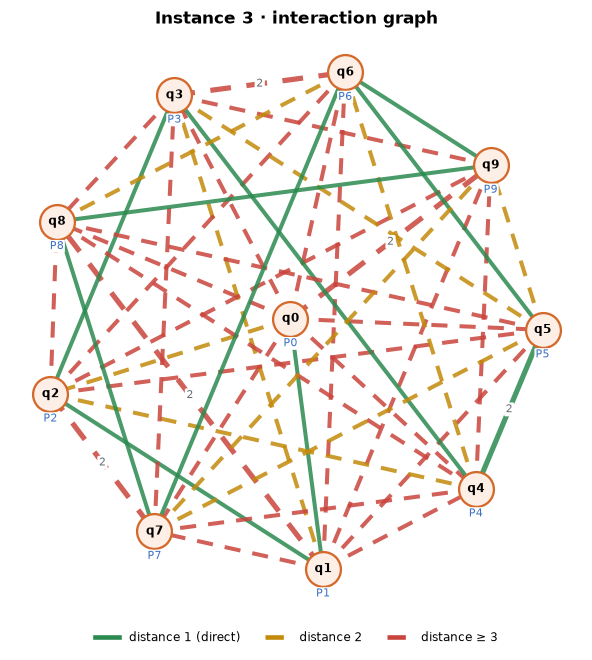

In [22]:
def interaction_layout(instance, seed=0):
    """Positions des sommets du graphe d'interaction, calculées par une disposition « ressorts » (networkx)."""
    graph = nx.Graph()
    graph.add_nodes_from(range(instance.n))
    graph.add_edges_from(map(tuple, instance.pairs))
    # k règle l'écartement des sommets ; seed rend la disposition identique d'une exécution à l'autre.
    return nx.spring_layout(graph, seed=seed, k=1.8 / math.sqrt(max(instance.n, 1)), iterations=500)


def plot_interaction_graph(instance, mapping, positions):
    """Dessine le graphe d'interaction coloré selon les distances physiques du placement."""
    fig, ax = plt.subplots(figsize=(7.5, 6.8))
    # Poids maximal, pour normaliser l'épaisseur des arêtes.
    max_weight = max(int(instance.weights.max()), 1)
    # Une arête par paire qui interagit : (a, b), son nombre de portes et sa distance physique.
    for (a, b), weight, distance in zip(instance.pairs, instance.weights, pair_distances(instance, mapping)):
        (xa, ya), (xb, yb) = positions[a], positions[b]
        # Trait plein si les qubits sont voisins sur la puce, pointillé sinon.
        style = "-" if distance == 1 else (0, (4, 3))
        ax.plot([xa, xb], [ya, yb], color=distance_color(distance), linewidth=0.8 + 2.6 * math.sqrt(weight / max_weight), linestyle=style, solid_capstyle="round", alpha=0.85, zorder=1)
        # Nombre de portes affiché au milieu de l'arête quand il dépasse 1.
        if weight > 1:
            ax.text((xa + xb) / 2, (ya + yb) / 2, str(weight), fontsize=7, color=MUTED, ha="center", va="center", bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none"}, zorder=2)
    # Les sommets : un disque orange par qubit logique, avec son qubit physique écrit dessous.
    for q, (x, y) in positions.items():
        ax.scatter(x, y, s=520, color=LOGICAL_SOFT, edgecolors=LOGICAL, linewidths=1.5, zorder=3)
        ax.text(x, y, f"q{q}", ha="center", va="center", fontsize=8, fontweight="bold", zorder=4)
        ax.annotate(f"P{mapping[q]}", (x, y), xytext=(0, -18), textcoords="offset points", ha="center", fontsize=7, color=PHYSICAL, bbox={"boxstyle": "round,pad=0.1", "fc": "white", "ec": "none"}, zorder=4)
    ax.set_title(f"Instance {instance.instance_id} · interaction graph")
    ax.set_aspect("equal")
    ax.margins(0.08)
    ax.set_axis_off()
    distance_legend(ax)
    return fig


# Calcul des positions puis dessin (le « ; » final évite d'afficher l'objet figure en texte).
positions = interaction_layout(instance)
plot_interaction_graph(instance, mapping, positions);

## 2. Puce et placement

Le graphe de couplage réel de la puce (bandes bleues). Les qubits physiques occupés montrent leur qubit logique ; les cercles en pointillés sont libres. Les interactions du circuit sont superposées : en trait plein si les deux qubits sont voisins, en pointillés courbés sinon (le routage devra ajouter des `SWAP`).

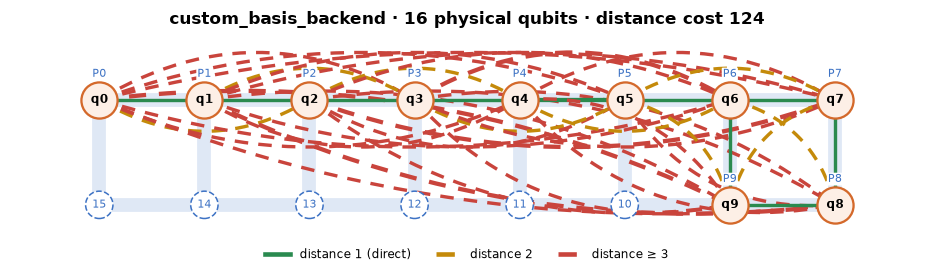

In [23]:
def curve_points(start, end, bend):
    """Points d'une courbe (Bézier quadratique) entre deux positions, décalée de `bend` sur le côté."""
    start, end = np.asarray(start), np.asarray(end)
    direction = end - start
    # Vecteur perpendiculaire unitaire, pour décaler le point de contrôle sur le côté.
    normal = np.array([-direction[1], direction[0]]) / (np.linalg.norm(direction) or 1)
    control = (start + end) / 2 + normal * bend
    # 30 points de paramètre t entre 0 et 1.
    t = np.linspace(0, 1, 30)[:, None]
    return (1 - t) ** 2 * start + 2 * (1 - t) * t * control + t ** 2 * end


def plot_hardware(instance, mapping, coordinates, show_interactions=True):
    """Dessine la puce, le placement et (optionnellement) les interactions du circuit superposées."""
    # Taille de la figure adaptée à l'étendue de la puce.
    width = np.ptp(coordinates[:, 0]) + 1
    height = np.ptp(coordinates[:, 1]) + 1
    fig, ax = plt.subplots(figsize=(1.15 * width + 1.5, 1.15 * height + 1.6))
    # Connexions physiques de la puce : bandes bleu clair.
    for a, b in instance.edges:
        ax.plot(*coordinates[[a, b]].T, color=PHYSICAL_SOFT, linewidth=9, solid_capstyle="round", zorder=1)
    if show_interactions:
        max_weight = max(int(instance.weights.max()), 1)
        for index, ((a, b), weight, distance) in enumerate(zip(instance.pairs, instance.weights, pair_distances(instance, mapping))):
            # Positions des qubits physiques des deux qubits logiques de la paire.
            start, end = coordinates[mapping[a]], coordinates[mapping[b]]
            line_width = 0.8 + 2 * math.sqrt(weight / max_weight)
            if distance == 1:
                # Voisins : trait droit vert, posé sur la connexion physique.
                ax.plot(*np.array([start, end]).T, color=distance_color(1), linewidth=line_width, zorder=2)
            else:
                # Non voisins : courbe en pointillés (alternativement d'un côté puis de l'autre pour limiter les chevauchements).
                bend = (0.3 if index % 2 else -0.3) * min(np.linalg.norm(end - start), 3)
                points = curve_points(start, end, bend)
                ax.plot(points[:, 0], points[:, 1], color=distance_color(distance), linewidth=line_width, linestyle=(0, (4, 3)), zorder=2)
    # Correspondance inverse : qubit physique -> qubit logique qui l'occupe.
    owner = {p: q for q, p in enumerate(mapping)}
    for p, (x, y) in enumerate(coordinates):
        if p in owner:
            # Qubit physique occupé : disque orange avec le qubit logique, numéro physique au-dessus.
            ax.scatter(x, y, s=560, color=LOGICAL_SOFT, edgecolors=LOGICAL, linewidths=1.5, zorder=3)
            ax.text(x, y, f"q{owner[p]}", ha="center", va="center", fontsize=8, fontweight="bold", zorder=4)
            ax.annotate(f"P{p}", (x, y), xytext=(0, 15), textcoords="offset points", ha="center", fontsize=7, color=PHYSICAL, bbox={"boxstyle": "round,pad=0.1", "fc": "white", "ec": "none"}, zorder=4)
        else:
            # Qubit physique libre : cercle blanc en pointillés avec son numéro.
            ax.scatter(x, y, s=320, color="white", edgecolors=PHYSICAL, linewidths=1, linestyle="--", zorder=3)
            ax.text(x, y, str(p), ha="center", va="center", fontsize=7, color=PHYSICAL, zorder=4)
    ax.set_title(f"{instance.hardware_name} · {instance.m} physical qubits · distance cost {distance_cost(instance, mapping)}")
    # Axe vertical inversé : la ligne 0 de la puce est dessinée en haut.
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.margins(0.12)
    ax.set_axis_off()
    distance_legend(ax)
    return fig


plot_hardware(instance, mapping, coordinates);

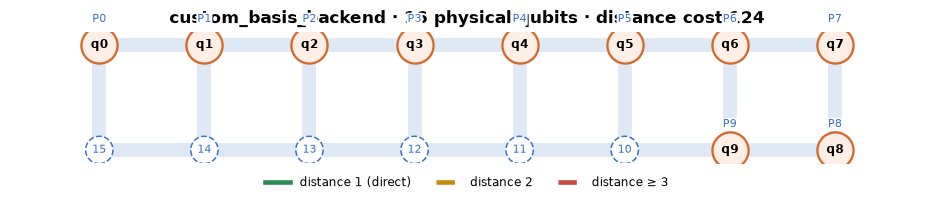

In [24]:
# La même puce sans les interactions : on voit seulement quel qubit logique occupe quel qubit physique.
plot_hardware(instance, mapping, coordinates, show_interactions=False);

## 3. Matrices

- **Gauche** : nombre de portes à 2 qubits entre chaque paire de qubits logiques (la matrice d'adjacence pondérée du graphe d'interaction).
- **Milieu** : distance sur la puce entre les qubits physiques de chaque paire, avec le placement choisi.
- **Droite** : le produit portes × (distance − 1), c'est-à-dire la contribution de chaque paire au coût de distance. Les cases rouges sont les paires à rapprocher en priorité.

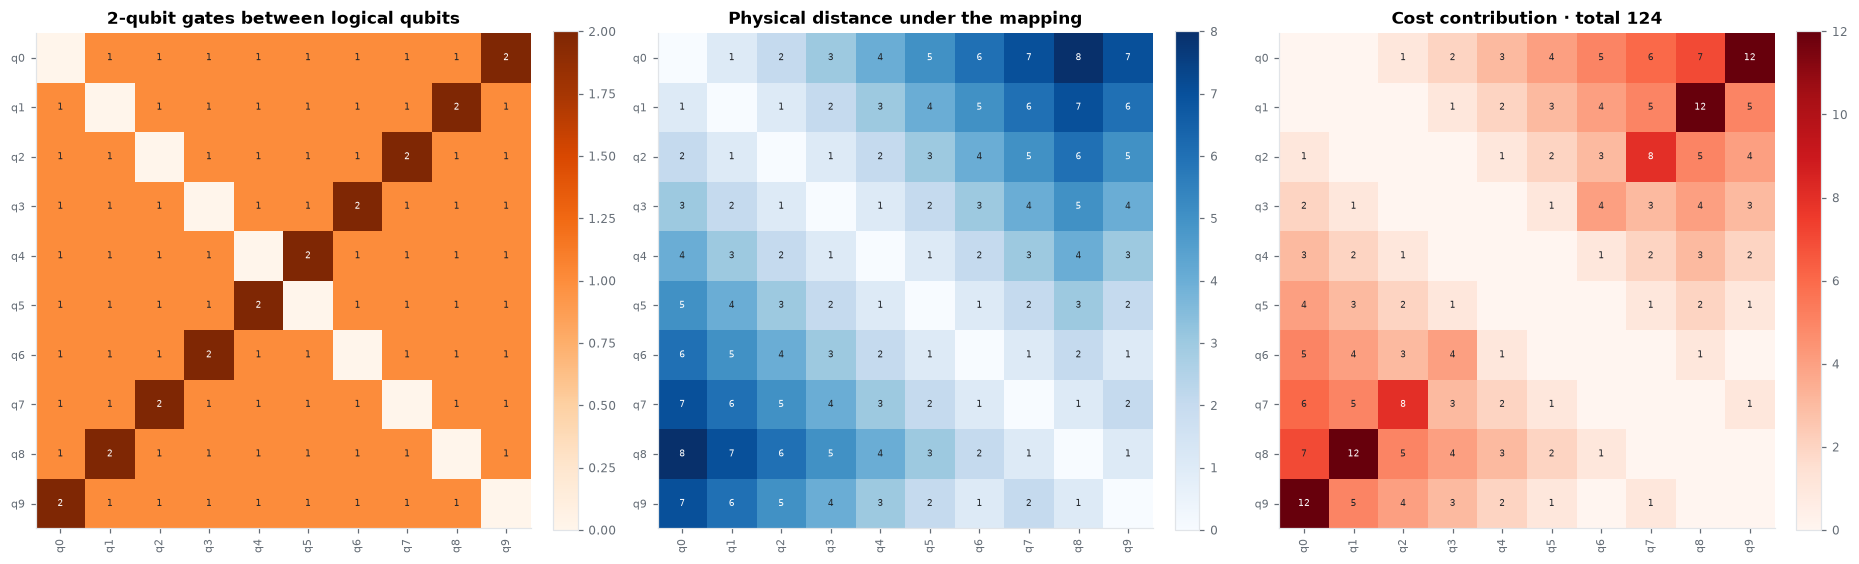

In [25]:
def interaction_matrix(instance):
    """Matrice n × n : nombre de portes à 2 qubits entre chaque paire de qubits logiques."""
    matrix = np.zeros((instance.n, instance.n), dtype=int)
    for (a, b), weight in zip(instance.pairs, instance.weights):
        matrix[a, b] = matrix[b, a] = weight
    return matrix


def heatmap(ax, matrix, title, cmap, labels, annotate):
    """Affiche une matrice en carte de chaleur, avec les valeurs écrites dans les cases si `annotate`."""
    image = ax.imshow(matrix, cmap=cmap)
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.grid(False)
    ax.set_title(title)
    if annotate:
        # Texte blanc sur les cases foncées, noir sur les claires.
        threshold = matrix.max() * 0.6
        for (i, j), value in np.ndenumerate(matrix):
            if value:
                ax.text(j, i, str(value), ha="center", va="center", fontsize=6, color="white" if value > threshold else "#1f2328")
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)


def plot_matrices(instance, mapping):
    """Les trois matrices côte à côte : portes, distances du placement, contributions au coût."""
    interactions = interaction_matrix(instance)
    # np.ix_ sélectionne les lignes et colonnes du placement : distance entre qubits physiques de chaque paire logique.
    mapped = instance.distances[np.ix_(mapping, mapping)]
    # Contribution = portes × (distance − 1) ; clip évite les valeurs négatives sur la diagonale (distance 0).
    contribution = interactions * np.clip(mapped - 1, 0, None)
    labels = [f"q{q}" for q in range(instance.n)]
    # Les valeurs ne sont écrites que si la matrice est assez petite pour rester lisible.
    annotate = instance.n <= 16
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
    heatmap(axes[0], interactions, "2-qubit gates between logical qubits", "Oranges", labels, annotate)
    heatmap(axes[1], mapped, "Physical distance under the mapping", "Blues", labels, annotate)
    # La matrice est symétrique : chaque paire est comptée deux fois, d'où la division par 2 pour le total.
    heatmap(axes[2], contribution, f"Cost contribution · total {contribution.sum() // 2}", "Reds", labels, annotate)
    fig.tight_layout()
    return fig


plot_matrices(instance, mapping);

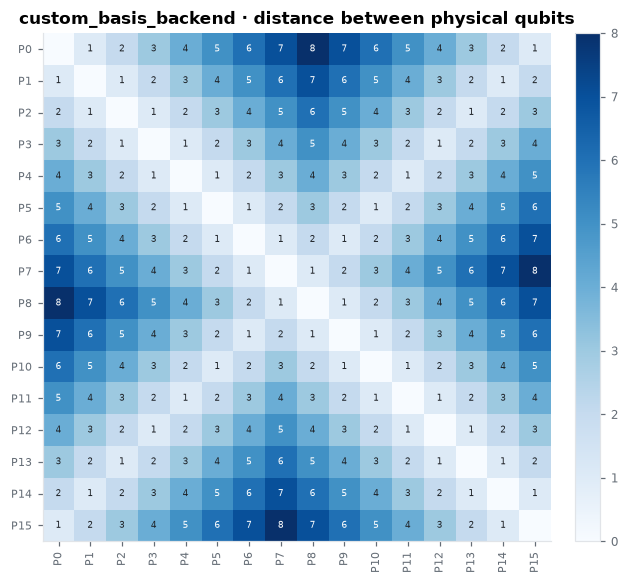

In [26]:
def plot_hardware_distances(instance):
    """Matrice m × m des distances entre qubits physiques (nombre de connexions à traverser)."""
    fig, ax = plt.subplots(figsize=(7, 6))
    heatmap(ax, instance.distances, f"{instance.hardware_name} · distance between physical qubits", "Blues", [f"P{p}" for p in range(instance.m)], instance.m <= 20)
    return fig


plot_hardware_distances(instance);

## 4. Degrés

Le **degré logique** est le nombre de partenaires distincts d'un qubit dans le circuit ; le **degré matériel**, le nombre de voisins d'un qubit sur la puce. Un qubit logique dont le degré dépasse le degré matériel maximal ne pourra **jamais** avoir tous ses partenaires adjacents : des `SWAP` sont alors inévitables.

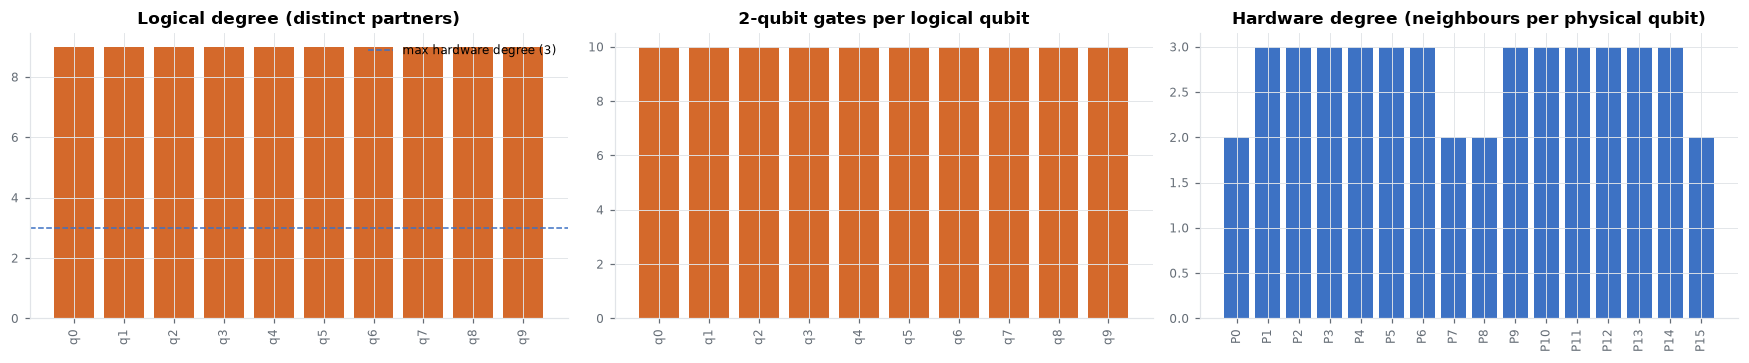

In [27]:
def plot_degrees(instance, hardware_degree):
    """Trois diagrammes : degré logique, portes par qubit logique, degré de chaque qubit physique."""
    logical_degree = instance.degrees()
    # Nombre de portes à 2 qubits de chaque qubit logique (on ajoute le poids de chaque paire à ses deux qubits).
    load = np.zeros(instance.n, dtype=int)
    np.add.at(load, instance.pairs[:, 0], instance.weights)
    np.add.at(load, instance.pairs[:, 1], instance.weights)
    logical_labels = [f"q{q}" for q in range(instance.n)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
    axes[0].bar(range(instance.n), logical_degree, color=LOGICAL)
    # Ligne pointillée : degré maximal possible sur la puce.
    axes[0].axhline(hardware_degree.max(), color=PHYSICAL, linestyle="--", linewidth=1, label=f"max hardware degree ({hardware_degree.max()})")
    axes[0].set_xticks(range(instance.n), logical_labels, rotation=90)
    axes[0].set_title("Logical degree (distinct partners)")
    axes[0].legend()
    axes[1].bar(range(instance.n), load, color=LOGICAL)
    axes[1].set_xticks(range(instance.n), logical_labels, rotation=90)
    axes[1].set_title("2-qubit gates per logical qubit")
    axes[2].bar(range(instance.m), hardware_degree, color=PHYSICAL)
    axes[2].set_xticks(range(instance.m), [f"P{p}" for p in range(instance.m)], rotation=90)
    axes[2].set_title("Hardware degree (neighbours per physical qubit)")
    fig.tight_layout()
    return fig


plot_degrees(instance, hardware_degree);

## 5. Circuit

Le dessin Qiskit montre toutes les portes du circuit logique (seulement s'il n'est pas trop grand). La **carte compacte** dessous range les portes en couches au plus tôt : chaque trait vertical est une porte à 2 qubits, colorée selon la distance physique de ses qubits avec le placement choisi ; les petits carrés gris sont les portes à 1 qubit.

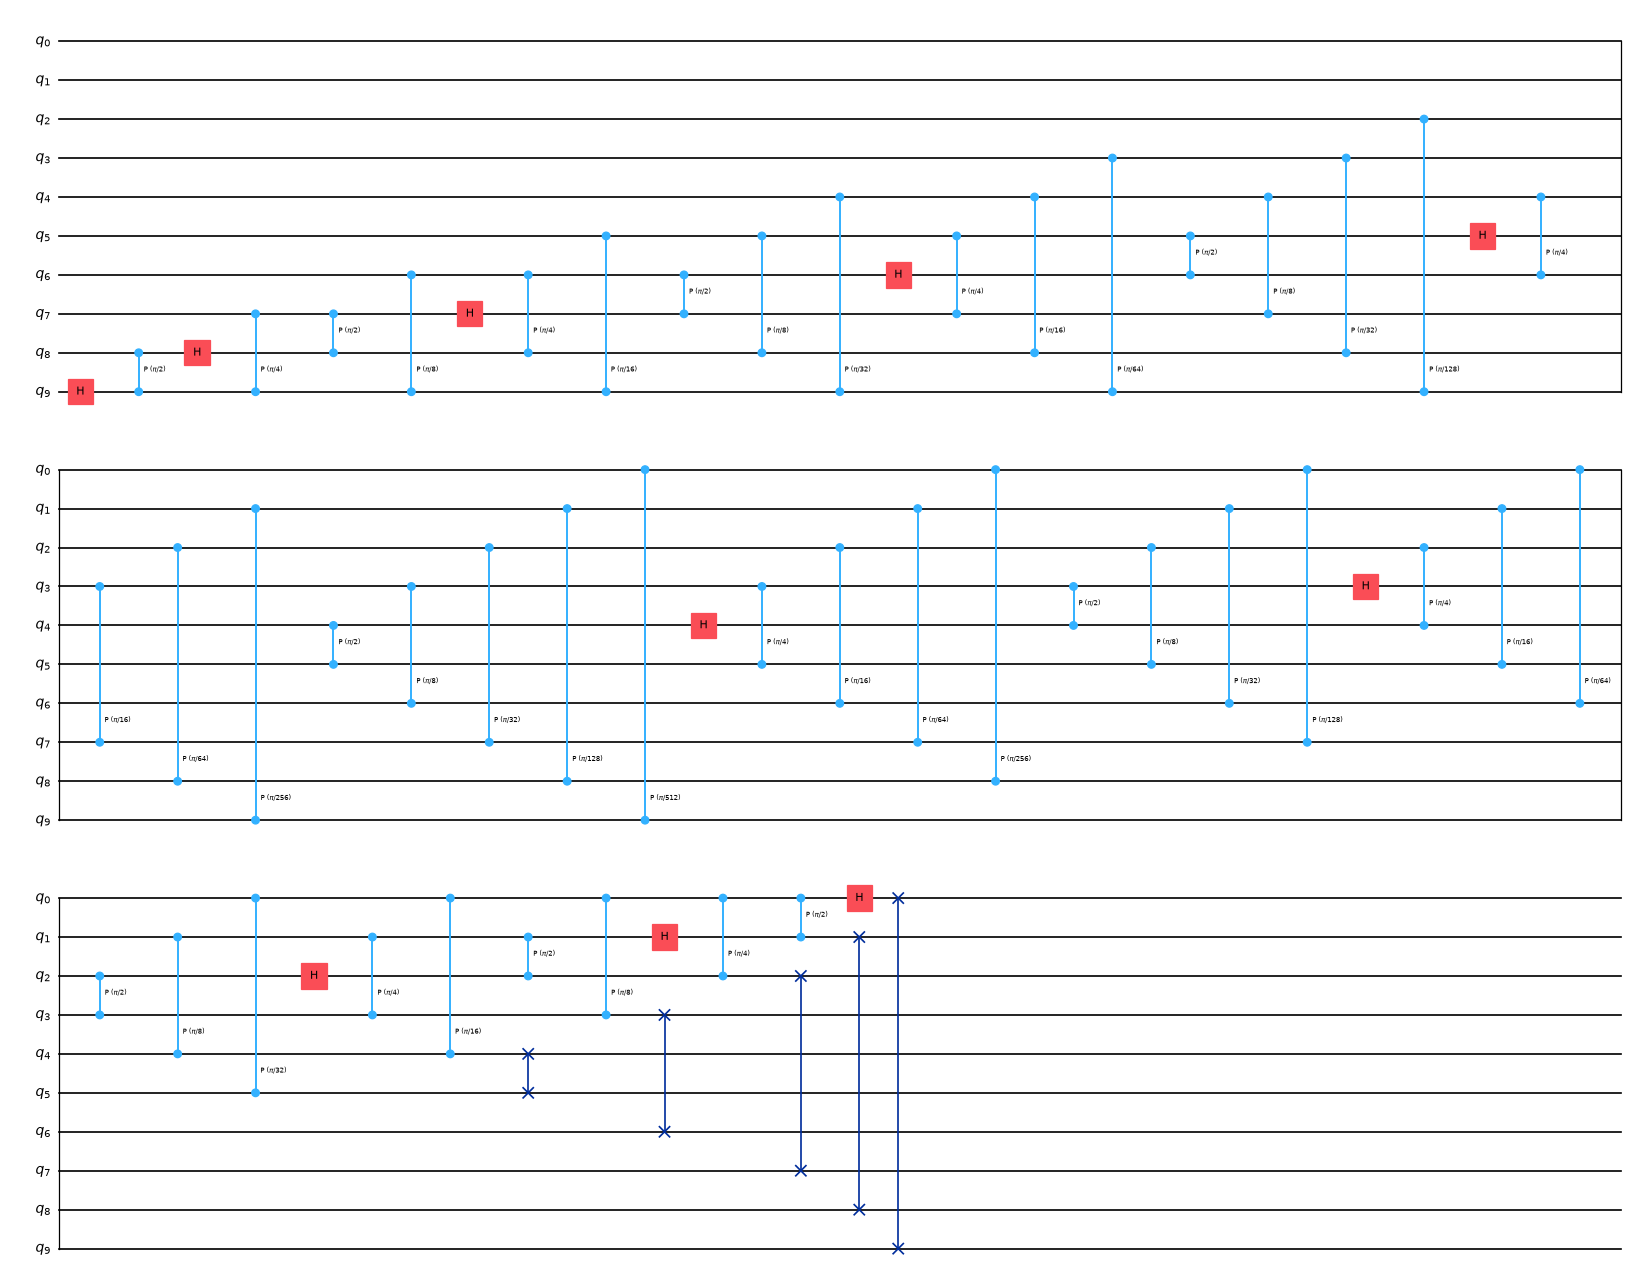

In [28]:
if logical_summary["size"] <= MAX_GATES_FOR_QISKIT_DRAWING:
    # Dessin Qiskit : fold=40 coupe le circuit en lignes de 40 colonnes, idle_wires=False masque les fils inutilisés.
    drawing = instance.circuit.draw("mpl", fold=40, scale=0.55, idle_wires=False)
    # On ferme la figure puis on l'affiche une seule fois (évite un double affichage).
    plt.close(drawing)
    display(drawing)
else:
    print(f"{logical_summary['size']} gates: too large for a readable Qiskit drawing, see the compact map below.")

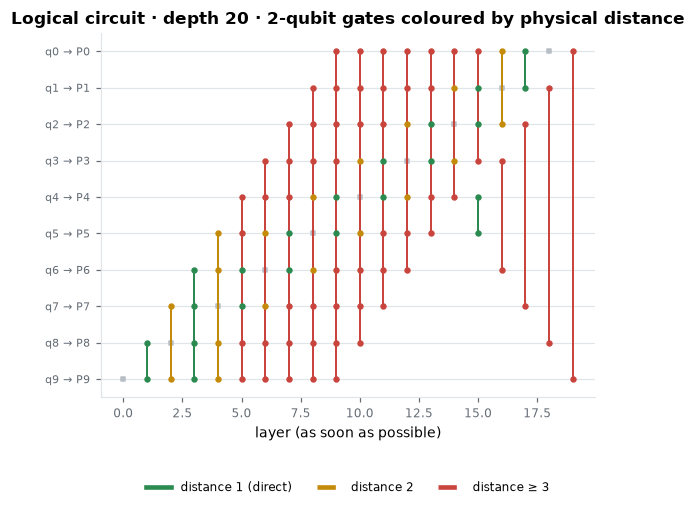

In [29]:
def asap_layers(operations, num_wires):
    """Range chaque porte dans la première couche où tous ses qubits sont libres (« au plus tôt »)."""
    # level[q] = première couche libre pour le qubit q.
    level = np.zeros(num_wires, dtype=int)
    placed = []
    for operation in operations:
        qubits = operation["qubits"]
        # La porte attend que tous ses qubits soient disponibles.
        layer = int(level[qubits].max())
        level[qubits] = layer + 1
        placed.append((layer, operation))
    return placed


def plot_gate_map(operations, wires, labels, colour_of, title):
    """Carte compacte d'un circuit : une ligne par fil, un trait vertical par porte à 2 qubits."""
    # Position verticale (ligne) de chaque fil.
    row = {wire: index for index, wire in enumerate(wires)}
    # Portes rangées en couches, en ne gardant que celles dont tous les qubits sont affichés.
    placed = [(layer, op) for layer, op in asap_layers(operations, max(wires) + 1) if all(q in row for q in op["qubits"])]
    depth = max((layer for layer, _ in placed), default=0) + 1
    fig, ax = plt.subplots(figsize=(min(18, 4 + depth * 0.09), 0.27 * len(wires) + 1.6))
    # Les fils (lignes horizontales).
    for index in range(len(wires)):
        ax.axhline(index, color=GRID, linewidth=0.8, zorder=0)
    # Portes à 1 qubit : petits carrés gris.
    single = [(layer, row[op["qubits"][0]]) for layer, op in placed if len(op["qubits"]) == 1]
    if single:
        xs, ys = zip(*single)
        ax.scatter(xs, ys, s=6, marker="s", color="#b8bec6", zorder=1)
    # Portes à 2 qubits : trait vertical entre les fils concernés, couleur donnée par colour_of.
    for layer, op in placed:
        if len(op["qubits"]) < 2:
            continue
        ys = [row[q] for q in op["qubits"]]
        colour = colour_of(op)
        ax.plot([layer, layer], [min(ys), max(ys)], color=colour, linewidth=1.3, zorder=2)
        ax.scatter([layer] * len(ys), ys, s=10, color=colour, zorder=3)
    ax.set_yticks(range(len(wires)), labels, fontsize=7)
    # Premier fil en haut.
    ax.set_ylim(len(wires) - 0.5, -0.5)
    ax.set_xlabel("layer (as soon as possible)")
    ax.grid(False)
    ax.set_title(title)
    return fig


def logical_gate_colour(operation):
    """Couleur d'une porte du circuit logique : la plus grande distance physique entre ses qubits."""
    qubits = operation["qubits"]
    return distance_color(max(instance.distances[mapping[a], mapping[b]] for a in qubits for b in qubits if a != b))


# Liste des portes du circuit logique, puis carte compacte avec le qubit physique de chaque fil.
logical_operations = circuit_data.operations(instance.circuit)
figure = plot_gate_map(
    logical_operations,
    list(range(instance.n)),
    [f"q{q} → P{mapping[q]}" for q in range(instance.n)],
    logical_gate_colour,
    f"Logical circuit · depth {logical_summary['depth']} · 2-qubit gates coloured by physical distance",
)
distance_legend(figure.axes[0], offset=-0.2)

## 6. Évaluation du placement

La vraie fitness (`source.fitness_inner`) est calculée `EVALUATION_RUNS` fois : elle varie d'une exécution à l'autre (voir le notebook 02).

In [34]:
# Problème sans budget : on peut évaluer autant qu'on veut.
problem = Problem(instance)
# EVALUATION_RUNS vraies évaluations du même placement.
costs = problem.fitness_samples(mapping, EVALUATION_RUNS)
# Récapitulatif converti en texte pour un affichage homogène.
evaluation_summary = pd.Series({
    "distance cost": distance_cost(instance, mapping),
    "direct 2-qubit gates": f"{direct_gate_ratio(instance, mapping):.0%}",
    "fitness min": min(costs),
    "fitness mean": round(float(np.mean(costs)), 2),
    "fitness max": max(costs),
    "fitness std": round(float(np.std(costs, ddof=1)), 2) if len(costs) > 1 else 0.0,
    "all runs": " ".join(map(str, costs)),
}, name="value").astype(str).to_frame()
evaluation_summary

,value
distance cost,124
direct 2-qubit gates,22%
fitness min,144
fitness mean,148.5
fitness max,150
fitness std,2.17
all runs,150 145 144 150 150 149 150 149 149 149


Paires du circuit triées par contribution au coût de distance :

In [33]:
# Une ligne par paire de qubits logiques qui interagissent.
pair_table = pd.DataFrame({
    "pair": [f"q{a}–q{b}" for a, b in instance.pairs],
    "physical": [f"P{mapping[a]}–P{mapping[b]}" for a, b in instance.pairs],
    "gates": instance.weights,
    "distance": pair_distances(instance, mapping),
})
# Contribution de la paire au coût de distance.
pair_table["cost"] = pair_table["gates"] * (pair_table["distance"] - 1)
# Tri : les paires les plus coûteuses en premier.
pair_table = pair_table.sort_values(["cost", "gates"], ascending=False).reset_index(drop=True)
pair_table

,pair,physical,gates,distance,cost
0,q0–q9,P0–P9,2,7,12
1,q1–q8,P1–P8,2,7,12
2,q2–q7,P2–P7,2,5,8
3,q0–q8,P0–P8,1,8,7
4,q0–q7,P0–P7,1,7,6
5,q0–q6,P0–P6,1,6,5
6,q1–q7,P1–P7,1,6,5
7,q1–q9,P1–P9,1,6,5
8,q2–q8,P2–P8,1,6,5
9,q3–q6,P3–P6,2,3,4


**Circuit routé.** Un exemple du circuit réellement produit par la chaîne de `fitness_inner` : il vit sur les qubits physiques. Les étiquettes donnent le qubit logique présent au début → à la fin (les `SWAP` déplacent les qubits logiques).

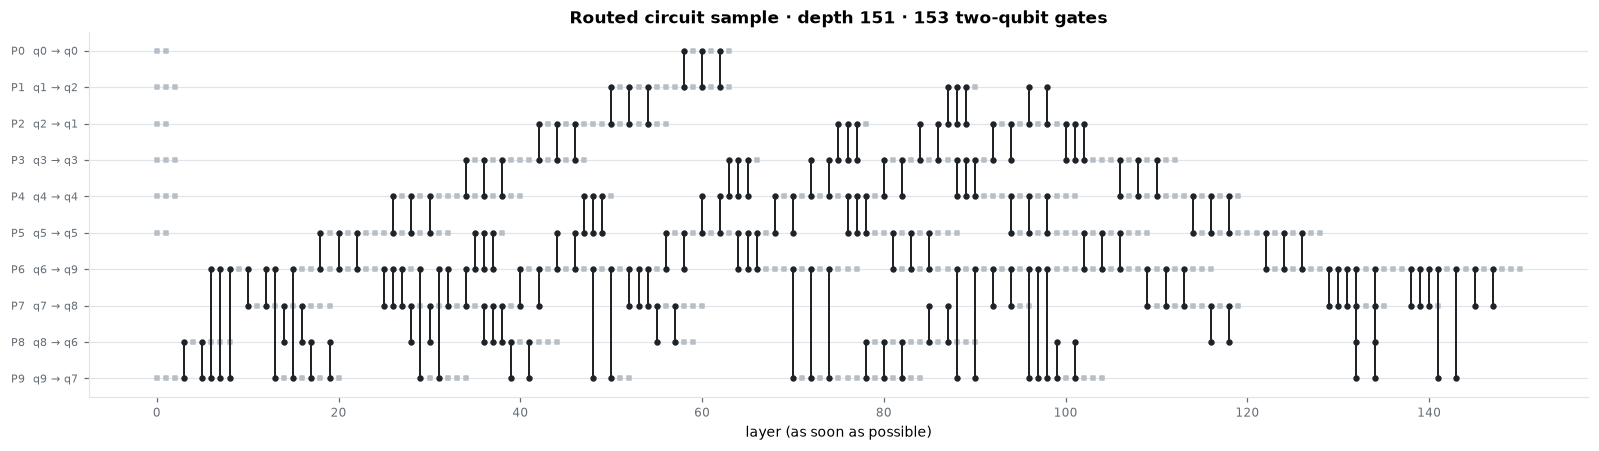

In [32]:
# Circuit après routage (même chaîne que fitness_inner), ses statistiques et ses portes.
routed = source_bridge.routed_circuit(mapping, instance.circuit, instance.backend)
routed_summary = circuit_data.summary(routed)
routed_operations = circuit_data.operations(routed)
try:
    # Placement final : où se trouve chaque qubit logique à la fin du circuit (après les SWAP).
    final_mapping = list(routed.layout.final_index_layout())[: instance.n]
except Exception:
    final_mapping = []
# Qubit logique présent sur chaque qubit physique au début et à la fin.
initial_owner = {p: q for q, p in enumerate(mapping)}
final_owner = {p: q for q, p in enumerate(final_mapping)}
# Fils à afficher : qubits physiques du placement ou utilisés par au moins une porte.
used = sorted(set(mapping) | {q for op in routed_operations for q in op["qubits"]})
labels = [f"P{p}  {'q' + str(initial_owner[p]) if p in initial_owner else '·'} → {'q' + str(final_owner[p]) if p in final_owner else '·'}" for p in used]
# Toutes les portes du circuit routé sont directes : on les dessine en noir.
plot_gate_map(routed_operations, used, labels, lambda op: "#1f2328", f"Routed circuit sample · depth {routed_summary['depth']} · {routed_summary['twoQubitGates']} two-qubit gates");